<a href="https://colab.research.google.com/github/Aryanshh/CSET343/blob/main/Lab8_1758.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# CELL 1: Install Required Libraries

!pip install pandas numpy nltk matplotlib seaborn wordcloud scikit-learn pyLDAvis requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.6/2.6 MB 9.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 43.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pyLDAvis]


In [2]:
# CELL 2: Import Required Libraries

import pandas as pd
import numpy as np
import re
import nltk
import requests
import json
import matplotlib.pyplot as plt
import seaborn as sns

from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
# CELL 3: Download NLTK Resources

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("NLTK resources downloaded successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


NLTK resources downloaded successfully!


In [4]:
# CELL 4: Load Healthcare Dataset

repo = "WuraolaOyewusi/Health-Related-Headlines-Datasets-for-Natural-Language-Processing"

api_url = f"https://api.github.com/repos/{repo}/git/trees/main?recursive=1"

response = requests.get(api_url)

if response.status_code != 200:
    api_url = f"https://api.github.com/repos/{repo}/git/trees/master?recursive=1"
    response = requests.get(api_url)

response.raise_for_status()

files = response.json()['tree']

# Find CSV and JSON files
data_files = [
    file['path'] for file in files
    if file['path'].lower().endswith(('.csv', '.json'))
]

print("Available dataset files:")
for file in data_files:
    print(file)

# Select the first available dataset
if not data_files:
    raise ValueError("No CSV or JSON dataset found in the repository.")

file_path = data_files[0]

raw_url = f"https://raw.githubusercontent.com/{repo}/main/{file_path}"

# Try master branch if main does not contain the file
dataset_response = requests.get(raw_url)

if dataset_response.status_code != 200:
    raw_url = f"https://raw.githubusercontent.com/{repo}/master/{file_path}"
    dataset_response = requests.get(raw_url)

dataset_response.raise_for_status()

# Load dataset
if file_path.lower().endswith('.csv'):
    from io import StringIO
    df = pd.read_csv(StringIO(dataset_response.text))
else:
    from io import StringIO
    df = pd.read_json(StringIO(dataset_response.text))

print("\nDataset loaded successfully!")
print("\nDataset Shape:", df.shape)

display(df.head())

Available dataset files:
Adult_Immunization_Features_Headlines.csv
Adult_Immunization_News_Headlines.csv
Adverse_Drug_Events_Related_Headlines.csv
Adverse_Drug_Reaction_Journals_Headlines.csv
Adverse_Drug_Reaction_News_Headlines.csv
Adverse_Drug_Reaction_Perspective_Headlines.csv
Antibiotic_Resistance_Journals_Headlines.csv
Antibiotic_Resistance_News_Headlines.csv
Antibiotic_Resistance_Perspective_Headlines.csv
Antibiotic_Resistance_Related_Headlines.csv
Clinical_Trials_Journals_Headlines.csv
Clinical_Trials_News_Headlines.csv
Clinical_Trials_Perspective_Headlines.csv
Clinical_Trials_Related_Headlines.csv
Health_Related_Headlines_Dataset.csv
Immunization_Related_Headlines.csv
Pain_Management_Journals_Headlines.csv
Pain_Management_News_Headlines.csv
Pain_Management_Related_Headlines.csv
Pain_management_Features_Headlines.csv
Patient_Safety_Journals_Headlines.csv
Patient_Safety_News_Headlines.csv
Patient_Safety_Perspective_Headlines.csv
Patient_Safety_Related_Headlines.csv
Peadiatric_Imm

,Date,Source,Headlines,Teaser
0,October 2004,Medscape Infectious Diseases,"Infectious Diseases: October 30, 2004","Dr. Bartlett reviews the latest on influenza, ..."
1,July 2004,Journal of the American Board of Family Medicine,Influenza Vaccination in Pregnancy,Are enough family physicians and obstetricians...
2,June 2004,Medscape Nurses,Bacterial Meningitis: A Deadly But Preventable...,Those whose lives have been touched by this le...
3,April 2004,Alimentary Pharmacology & Therapeutics,Hepatitis Vaccination in Patients With Chronic...,Despite a declining incidence of acute viral h...
4,November 2003,Medscape Infectious Diseases,Emerging Infections,Dr. John Bartlett reports on the latest data f...


In [5]:
# CELL 5: Select and Combine Text Columns

print("Dataset Columns:")
print(df.columns.tolist())

# Identify healthcare text columns
text_keywords = ['headline', 'title', 'teaser', 'description', 'text', 'content']

text_columns = [
    col for col in df.columns
    if any(keyword in col.lower() for keyword in text_keywords)
]

if not text_columns:
    text_columns = df.select_dtypes(include=['object']).columns.tolist()

if not text_columns:
    raise ValueError("No suitable text columns found.")

print("\nSelected Text Columns:", text_columns)

# Combine selected text columns
df['text'] = df[text_columns].fillna('').astype(str).agg(' '.join, axis=1)

# Remove empty records
df = df[df['text'].str.strip() != ''].copy()

print("\nCombined Text Samples:")
display(df[['text']].head())

Dataset Columns:
['Date', 'Source', 'Headlines', 'Teaser']

Selected Text Columns: ['Headlines', 'Teaser']

Combined Text Samples:


,text
0,"Infectious Diseases: October 30, 2004 Dr. Bart..."
1,Influenza Vaccination in Pregnancy Are enough ...
2,Bacterial Meningitis: A Deadly But Preventable...
3,Hepatitis Vaccination in Patients With Chronic...
4,Emerging Infections Dr. John Bartlett reports ...


In [6]:
# CELL 6: Text Preprocessing and Cleaning

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_text(text):

    # Lowercasing
    text = text.lower()

    # Remove punctuation and special characters
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Tokenization
    tokens = word_tokenize(text)

    # Stop-word removal and lemmatization
    cleaned_tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
        if word not in stop_words and len(word) > 2
    ]

    return cleaned_tokens

# Apply preprocessing
df['cleaned_tokens'] = df['text'].apply(preprocess_text)

# Convert tokens into cleaned text
df['cleaned_text'] = df['cleaned_tokens'].apply(
    lambda tokens: ' '.join(tokens)
)

print("Text preprocessing completed!")

print("\nOriginal and Cleaned Text Samples:")
display(df[['text', 'cleaned_text']].head())

Text preprocessing completed!

Original and Cleaned Text Samples:


,text,cleaned_text
0,"Infectious Diseases: October 30, 2004 Dr. Bart...",infectious disease october bartlett review lat...
1,Influenza Vaccination in Pregnancy Are enough ...,influenza vaccination pregnancy enough family ...
2,Bacterial Meningitis: A Deadly But Preventable...,bacterial meningitis deadly preventable diseas...
3,Hepatitis Vaccination in Patients With Chronic...,hepatitis vaccination patient chronic liver di...
4,Emerging Infections Dr. John Bartlett reports ...,emerging infection john bartlett report latest...


In [7]:
# CELL 7: Generate Word Frequency Distribution

from collections import Counter

# Combine all cleaned tokens
all_words = []

for tokens in df['cleaned_tokens']:
    all_words.extend(tokens)

# Calculate word frequencies
word_freq = Counter(all_words)

# Display top 20 frequent words
top_20_words = word_freq.most_common(20)

frequency_df = pd.DataFrame(
    top_20_words,
    columns=['Word', 'Frequency']
)

print("Top 20 Most Frequent Words:")
display(frequency_df)

Top 20 Most Frequent Words:


,Word,Frequency
0,vaccine,253
1,influenza,160
2,flu,102
3,vaccination,91
4,new,87
5,patient,80
6,disease,64
7,adult,62
8,recommendation,55
9,hpv,52


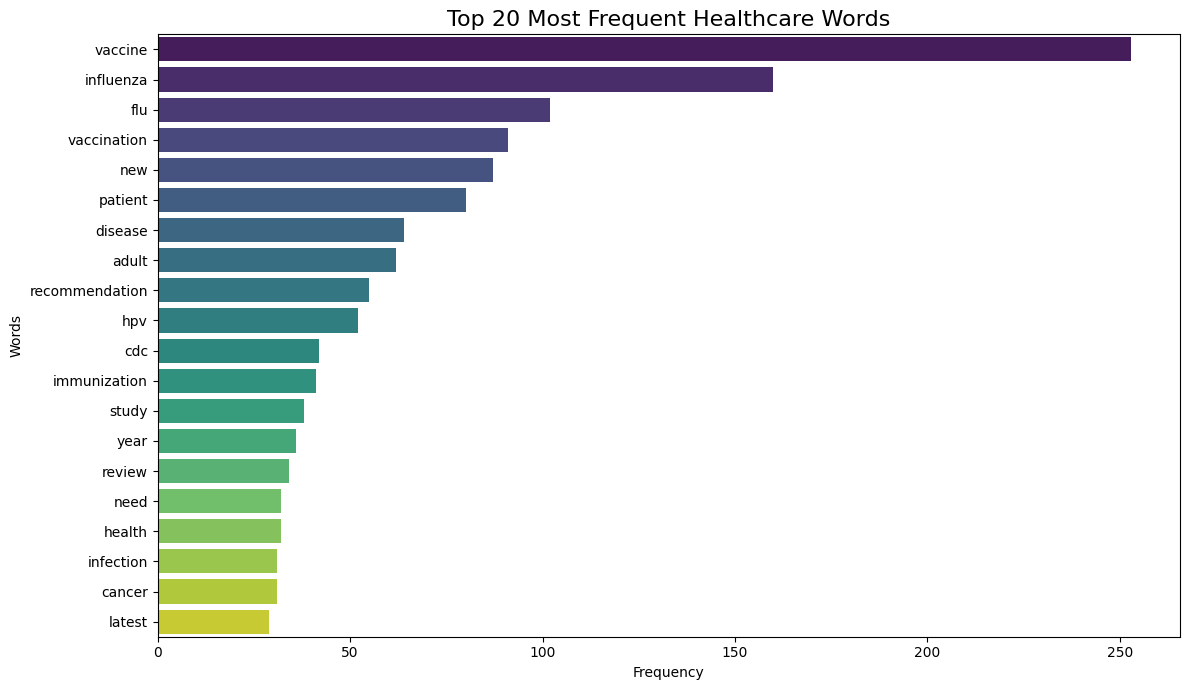

In [8]:
# CELL 8: Plot Top 20 Frequent Words

plt.figure(figsize=(12, 7))

sns.barplot(
    data=frequency_df,
    x='Frequency',
    y='Word',
    palette='viridis'
)

plt.title('Top 20 Most Frequent Healthcare Words', fontsize=16)
plt.xlabel('Frequency')
plt.ylabel('Words')

plt.tight_layout()
plt.show()

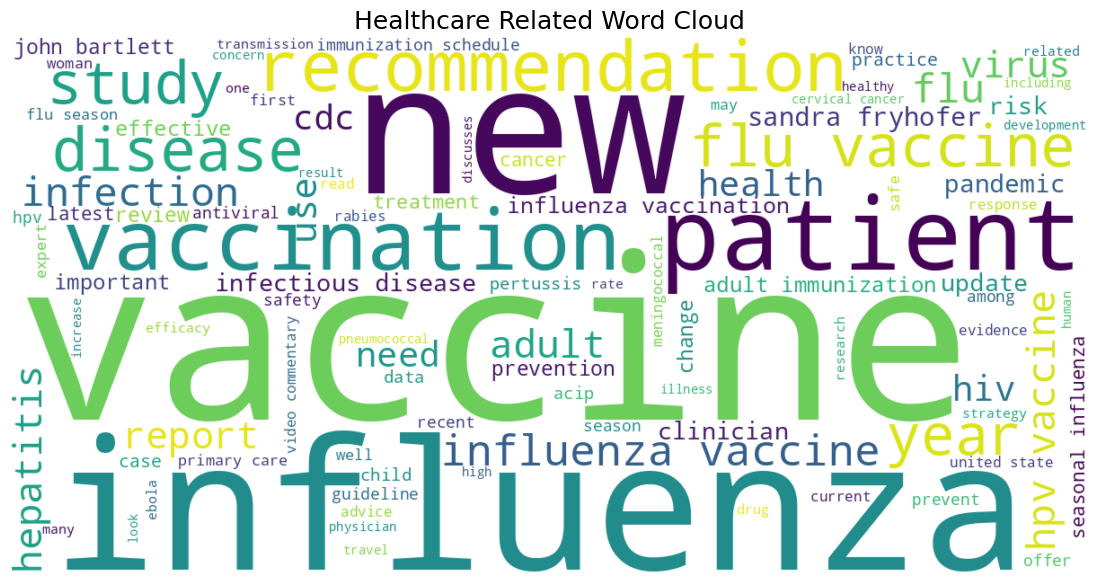

In [9]:
# CELL 9: Generate Word Cloud

text_data = ' '.join(all_words)

wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color='white',
    colormap='viridis',
    max_words=100
).generate(text_data)

plt.figure(figsize=(15, 7))

plt.imshow(wordcloud, interpolation='bilinear')

plt.axis('off')

plt.title('Healthcare Related Word Cloud', fontsize=18)

plt.show()

In [10]:
# CELL 10: Create Document-Term Matrix

vectorizer = CountVectorizer(
    max_features=1000,
    min_df=1,
    max_df=0.95
)

doc_term_matrix = vectorizer.fit_transform(df['cleaned_text'])

print("Document-Term Matrix Created Successfully!")

print("Matrix Shape:", doc_term_matrix.shape)

print("Number of Documents:", doc_term_matrix.shape[0])

print("Number of Unique Words:", doc_term_matrix.shape[1])

Document-Term Matrix Created Successfully!
Matrix Shape: (366, 1000)
Number of Documents: 366
Number of Unique Words: 1000


In [11]:
# CELL 11: Apply LDA Topic Modelling

# Number of topics
num_topics = 5

# Create LDA model
lda_model = LatentDirichletAllocation(
    n_components=num_topics,
    random_state=42,
    learning_method='batch',
    max_iter=10
)

# Train the model
lda_model.fit(doc_term_matrix)

print("LDA Model Trained Successfully!")

LDA Model Trained Successfully!
